<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/Latihan_BAB10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Membaca dataset (Pastikan file 'Mall_Customers.csv' sudah ada di panel Files kiri Colab)
df = pd.read_csv('Mall_Customers.csv')
print("Dataset berhasil dimuat!")
print(df.head())

Dataset berhasil dimuat!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


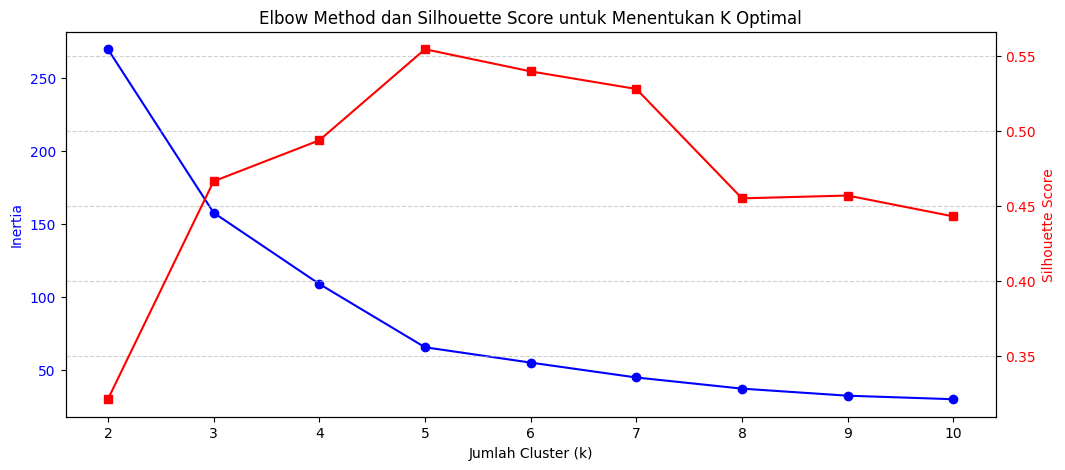

k = 2, Silhouette Score = 0.3213
k = 3, Silhouette Score = 0.4666
k = 4, Silhouette Score = 0.4939
k = 5, Silhouette Score = 0.5547
k = 6, Silhouette Score = 0.5399
k = 7, Silhouette Score = 0.5281
k = 8, Silhouette Score = 0.4552
k = 9, Silhouette Score = 0.4571
k = 10, Silhouette Score = 0.4432


In [4]:
# Mengambil fitur yang relevan untuk clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Standarisasi data (Sangat disarankan untuk K-Means dan DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menyiapkan list untuk menampung nilai
inertia = []
silhouette_scores = []
K_range = range(2, 11) # k=2 hingga k=10

for k in K_range:
    # 1. K-Means untuk Elbow Method
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

    # 2. Silhouette Score
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Visualisasi
fig, ax1 = plt.subplots(figsize=(12, 5))

# Plot Elbow Method
ax1.plot(K_range, inertia, marker='o', color='b', label='Inertia (Elbow)')
ax1.set_xlabel('Jumlah Cluster (k)')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Plot Silhouette Score (menggunakan sumbu Y kedua)
ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, marker='s', color='r', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Elbow Method dan Silhouette Score untuk Menentukan K Optimal')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Menampilkan nilai Silhouette secara numerik
for k, score in zip(K_range, silhouette_scores):
    print(f"k = {k}, Silhouette Score = {score:.4f}")

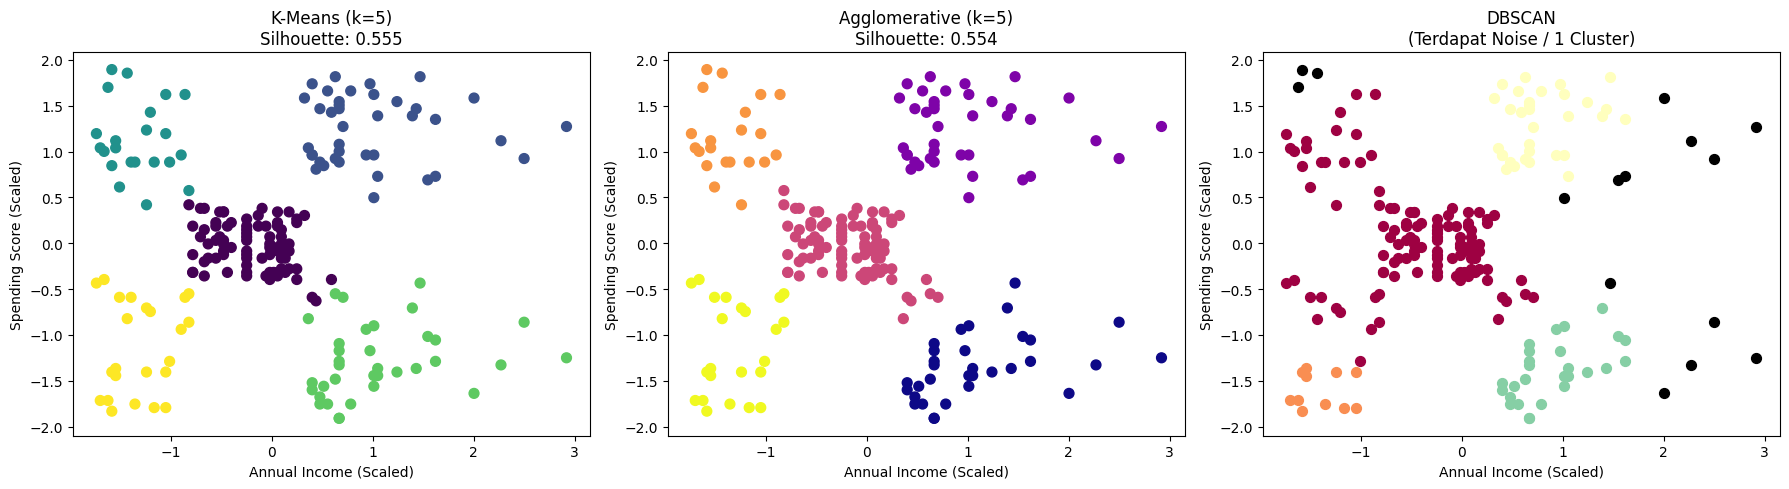

Jumlah cluster K-Means: 5
Jumlah cluster Agglomerative: 5
Jumlah cluster DBSCAN: 5 (termasuk noise jika ada)


In [5]:
# 1. Terapkan K-Means (k=5)
kmeans_opt = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_kmeans = kmeans_opt.fit_predict(X_scaled)

# 2. Terapkan Agglomerative Clustering (k=5)
agg_clustering = AgglomerativeClustering(n_clusters=5)
labels_agg = agg_clustering.fit_predict(X_scaled)

# 3. Terapkan DBSCAN
# Parameter eps dan min_samples perlu di-tuning.
# eps=0.4 dan min_samples=5 adalah nilai awal yang cukup baik untuk data yang sudah di-scale.
dbscan = DBSCAN(eps=0.4, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

# Visualisasi Perbandingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot K-Means
axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_kmeans, cmap='viridis', s=50)
axes[0].set_title(f'K-Means (k=5)\nSilhouette: {silhouette_score(X_scaled, labels_kmeans):.3f}')
axes[0].set_xlabel('Annual Income (Scaled)')
axes[0].set_ylabel('Spending Score (Scaled)')

# Plot Agglomerative
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_agg, cmap='plasma', s=50)
axes[1].set_title(f'Agglomerative (k=5)\nSilhouette: {silhouette_score(X_scaled, labels_agg):.3f}')
axes[1].set_xlabel('Annual Income (Scaled)')
axes[1].set_ylabel('Spending Score (Scaled)')

# Plot DBSCAN
# DBSCAN bisa menghasilkan noise (label -1), kita beri warna abu-abu
unique_labels = set(labels_dbscan)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1] # Hitam untuk noise
    class_member_mask = (labels_dbscan == k)
    xy = X_scaled[class_member_mask]
    axes[2].scatter(xy[:, 0], xy[:, 1], c=[col], s=50)

# Hitung silhouette DBSCAN (hanya jika ada lebih dari 1 cluster dan bukan semua noise)
if len(set(labels_dbscan)) > 1 and -1 not in set(labels_dbscan):
     sil_dbscan = silhouette_score(X_scaled, labels_dbscan)
     title_dbscan = f'DBSCAN\nSilhouette: {sil_dbscan:.3f}'
else:
     title_dbscan = 'DBSCAN\n(Terdapat Noise / 1 Cluster)'

axes[2].set_title(title_dbscan)
axes[2].set_xlabel('Annual Income (Scaled)')
axes[2].set_ylabel('Spending Score (Scaled)')

plt.tight_layout()
plt.show()

# Output jumlah cluster
print(f"Jumlah cluster K-Means: {len(set(labels_kmeans))}")
print(f"Jumlah cluster Agglomerative: {len(set(labels_agg))}")
print(f"Jumlah cluster DBSCAN: {len(set(labels_dbscan))} (termasuk noise jika ada)")